# CufflessAI: from PPG to blood pressure estimates

This walkthrough covers the completed educational pipeline: load the dataset, prepare signals and labels, extract PPG features, train selected models, evaluate train/validation predictions, and predict from PPG alone. Every stage calls shared Python code.

**Run All defaults to saved findings and a small CPU prediction example.** Full preparation and training are explicit optional steps. Download `selected-v1.zip` from the repository's Releases and extract it under `artifacts/` before running predictions. Setup commands are in the [setup guide](../SETUP.md).

The recommended model is **80% multi-task ResNet + 13% short CNN C + 7% LightGBM**. Recording splits do not establish patient independence, and the test set remains reserved.

In [1]:
from pathlib import Path
import json
import sys
import subprocess
from datetime import datetime

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'configs/selected_models.json').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook inside the project checkout.')
sys.path.insert(0, str(ROOT))
import torch
torch.set_num_threads(2)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

CONFIG = json.loads((ROOT / 'configs/selected_models.json').read_text())
ARTIFACTS = ROOT / 'artifacts/selected-v1'
HAVE_BUNDLE = (ARTIFACTS / 'config.json').is_file()
SEED = 2026
DEVICE = 'cpu'
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S')
RUN_ROOT = ROOT / 'data/derived/walkthrough' / RUN_ID
DATA_DIR = RUN_ROOT / 'prepared'       # or an existing verified prepared cohort
INPUTS_DIR = RUN_ROOT / 'selected_inputs'
TRAINED_DIR = RUN_ROOT / 'models'

REBUILD_ARCHIVE = False
RUN_PREPARATION = False
RUN_TRAINING = False
RUN_EVALUATION = False
TRAIN_MODEL = 'recommended'           # recommended, resnet_l1, lightgbm_16, or all

print('Model seed:', SEED, '| Prediction device:', DEVICE)
print('Saved model bundle:', 'available' if HAVE_BUNDLE else 'download/extract selected-v1.zip to artifacts/')

Model seed: 2026 | Prediction device: cpu
Saved model bundle: available


## 1. Load and identify the source data

The public UCI release has 12,000 synchronized PPG/ABP/ECG recordings sampled at 125 Hz. Five-second windows contain 625 samples. PPG is the model input; ABP supplies reference labels; ECG is outside the current models.

The source archive preserves all original signals and saved recording assignments. Fourteen later exact-record copies are excluded from modeling. Stable window IDs keep every signal, feature, and answer aligned. Overall EDA preceded split reservation; record IDs are not verified patient IDs.

For a full rebuild, put `Part_1.mat` through `Part_4.mat` in `data/raw/` and set `REBUILD_ARCHIVE=True`. This optional ingestion step preserves source values; later preparation and fitting use only train/validation recordings.

In [2]:
display(pd.DataFrame({
    'split': ['train', 'validation', 'test (reserved)'],
    'retained_windows': [363965, 75601, None],
    'included_recordings': [8273, 1769, None],
}))
if REBUILD_ARCHIVE:
    subprocess.run([sys.executable, str(ROOT / 'data/load_files.py')], cwd=ROOT, check=True)
else:
    print('Full archive build skipped. The downloadable example needs no raw dataset.')

,split,retained_windows,included_recordings
0,train,363965.0,8273.0
1,validation,75601.0,1769.0
2,test (reserved),NaN,NaN


Full archive build skipped. The downloadable example needs no raw dataset.


## 2. Clean signals, derive labels, and extract features

The accepted preparation interpolates small zero gaps, applies the NeuroKit Elgendi PPG path, and filters ABP at 40 Hz. PR41 labels use separate medians of prominent systolic peaks and interpeak minima over complete beat pairs. The reviewed repeated-maximum clipping rule and pressure bounds retain explicit exclusion reasons.

These rules received bounded engineering review, not clinical annotation. Small pulses can be missed; spikes and drift can remain. No ID, ABP diagnostic, or label is a PPG feature.

Set `RUN_PREPARATION=True` to run cleaning and Input C preparation. This requires the source archive/raw files and substantial runtime; the completed cleaning/export took about 50 minutes on the original machine. Each notebook run selects a new output directory. To reuse existing preparation, edit `DATA_DIR` and `INPUTS_DIR` above.

In [3]:
if RUN_PREPARATION:
    from cleaning.clean_data import prepare
    from cleaning.verify_artifacts import verify
    from models.selected_inputs import prepare_selected_inputs
    preparation_config = json.loads((ROOT / 'configs/pipeline.json').read_text())
    coverage = prepare(DATA_DIR, preparation_config, workers=4)
    verify(DATA_DIR)
    prepare_selected_inputs(DATA_DIR, INPUTS_DIR, CONFIG, workers=4)
    display(pd.DataFrame(coverage['coverage']))
else:
    print('Full preparation skipped; existing frozen inputs and labels are preserved.')

Full preparation skipped; existing frozen inputs and labels are preserved.


## 3. Inspect the two PPG input paths

Both selected networks use **Input C**: odd reflection, 0.5-8 Hz bandpass, and PPG/first/second derivative channels with the frozen edge handling. LightGBM uses fourteen NeuroKit/morphology features plus two pulse-shape additions. The fourteen features retain float64 calculations; the two additions use the float32 cleaned cache, matching training.

The bundled examples are a small slice of public **training** data. Their reference pressures are displayed only for illustration. Prediction preparation receives PPG alone; ABP-based training exclusions cannot be applied at inference.

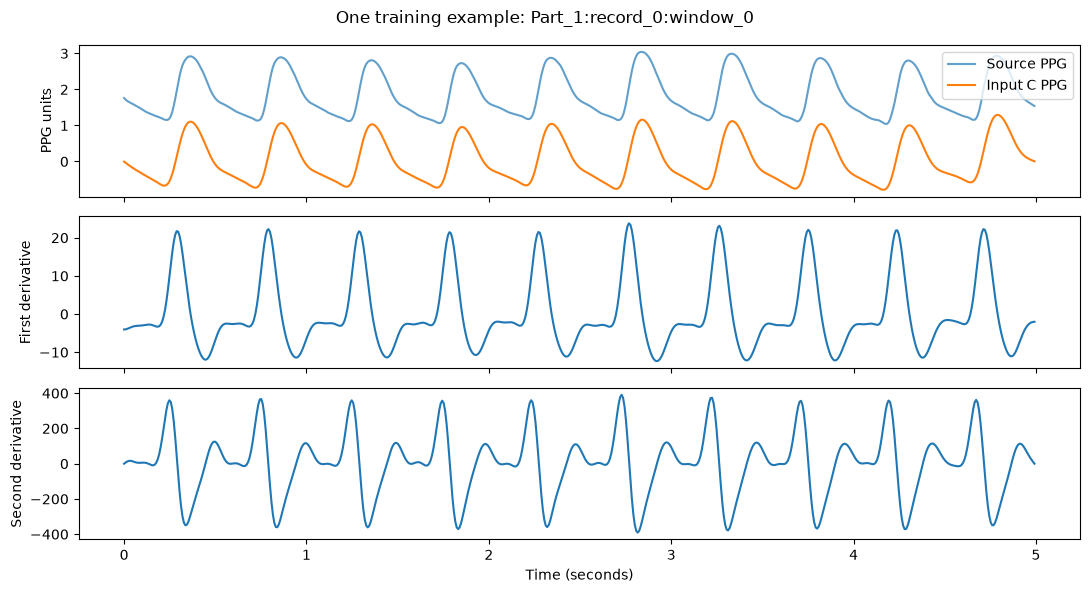

,ppg_clean_mean,ppg_clean_std,ppg_clean_range,median_interpeak_interval_s,median_rate_bpm,median_pulse_amplitude,median_rise_time_s,median_decay_time_s,median_rise_slope,median_decay_slope,median_half_amplitude_width_s,median_pulse_area,pulse_amplitude_cv,median_pulse_skewness,median_post_peak_area_fraction,median_normalized_max_upstroke_slope
0,-0.0112,0.6042,2.0604,0.496,120.9677,1.7729,0.144,0.352,12.5847,5.0867,0.1751,0.3540,0.0472,0.5612,0.6417,1.7787
1,0.0002,0.6020,2.0340,0.480,125.0000,1.8060,0.144,0.336,12.7116,5.3823,0.1740,0.3598,0.0309,0.5305,0.6412,1.7579
2,0.0503,0.6578,2.8600,0.488,122.9508,1.8065,0.144,0.344,12.5080,5.3059,0.1769,0.3630,0.0354,0.5289,0.6401,1.7836
3,-0.0488,0.6482,2.4278,0.488,122.9508,1.8167,0.144,0.344,12.6945,5.2720,0.1729,0.3605,0.0350,0.5650,0.6501,1.7566


In [4]:
if HAVE_BUNDLE:
    from models.selected_inputs import prepare_prediction_inputs
    with np.load(ARTIFACTS / 'samples/ppg.npz', allow_pickle=False) as saved:
        ppg, window_ids = saved['ppg'], saved['window_ids']
    positions, prepared_waveforms, feature_rows, reasons = prepare_prediction_inputs(ppg)
    time_s = np.arange(625) / 125
    fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
    axes[0].plot(time_s, ppg[0], label='Source PPG', alpha=0.7)
    axes[0].plot(time_s, prepared_waveforms[0, 0], label='Input C PPG')
    axes[0].legend(loc='upper right')
    axes[0].set_ylabel('PPG units')
    axes[1].plot(time_s, prepared_waveforms[0, 1]); axes[1].set_ylabel('First derivative')
    axes[2].plot(time_s, prepared_waveforms[0, 2]); axes[2].set_ylabel('Second derivative')
    axes[2].set_xlabel('Time (seconds)')
    fig.suptitle('One training example: ' + str(window_ids[0]))
    fig.tight_layout(); plt.show()
    display(feature_rows.head(4).round(4))
else:
    print('Extract the model bundle to run the PPG example.')

## 4. Try the recommended ensemble first

The loader verifies the selected weights and fitted preprocessing. Reuse the loaded predictor across calls; it does not train. Predictions remain in mmHg with the original IDs. Invalid PPG rows keep their ID and a rejection reason.

The final ensemble's three-seed validation MAE is **11.384 SBP / 5.806 DBP mmHg**. The example below uses seed 2026 and training examples, so its errors are not that validation result.

In [5]:
from models.selected_models import load_selected_model
if HAVE_BUNDLE:
    recommended = load_selected_model('recommended', SEED, ARTIFACTS, DEVICE)
    recommended_predictions = recommended.predict_ppg(ppg, window_ids)
    references = pd.read_csv(ARTIFACTS / 'samples/references.csv')
    example = references.merge(recommended_predictions, on='window_id', validate='one_to_one')
    display(example[['window_id', 'sbp', 'predicted_sbp', 'dbp', 'predicted_dbp', 'rejection_reason']].head(8).round(3))

,window_id,sbp,predicted_sbp,dbp,predicted_dbp,rejection_reason
0,Part_1:record_0:window_0,121.618,125.301,67.076,69.631,
1,Part_1:record_0:window_1,124.368,127.710,68.807,70.050,
2,Part_1:record_0:window_2,125.810,130.129,69.792,71.411,
3,Part_1:record_0:window_3,122.991,128.983,67.567,72.007,
4,Part_1:record_0:window_4,125.677,130.230,69.262,73.212,
5,Part_1:record_0:window_5,128.614,126.698,69.353,70.790,
6,Part_1:record_0:window_6,126.581,126.390,69.363,71.155,
7,Part_1:record_0:window_7,128.864,131.001,70.291,70.457,


## 5. Try the selected standalone alternatives

The L1 ResNet provides the stronger standalone waveform comparison. LightGBM provides a feature-based comparison and is also one component of the ensemble. These are separate saved choices, not additional tuning steps. Architecture, exact feature order, and per-seed durations are recorded in `configs/selected_models.json`.

In [6]:
if HAVE_BUNDLE:
    resnet = load_selected_model('resnet_l1', SEED, ARTIFACTS, DEVICE)
    display(resnet.predict_ppg(ppg, window_ids).head(4).round(3))

,window_id,predicted_sbp,predicted_dbp,rejection_reason
0,Part_1:record_0:window_0,124.208,69.712,
1,Part_1:record_0:window_1,126.506,69.038,
2,Part_1:record_0:window_2,128.155,68.834,
3,Part_1:record_0:window_3,123.190,67.995,


In [7]:
if HAVE_BUNDLE:
    lightgbm = load_selected_model('lightgbm_16', SEED, ARTIFACTS, DEVICE)
    display(lightgbm.predict_ppg(ppg, window_ids).head(4).round(3))

,window_id,predicted_sbp,predicted_dbp,rejection_reason
0,Part_1:record_0:window_0,129.985,73.301,
1,Part_1:record_0:window_1,128.703,72.993,
2,Part_1:record_0:window_2,131.017,72.872,
3,Part_1:record_0:window_3,133.702,71.033,


## 6. Optional: train a fresh selected model

The shared runner uses frozen settings and recorded durations, with preprocessing fitted on training only. It performs no search and does not stop on original validation. The selected ResNets use kernel seven, widths 16/32/64, AdamW (learning rate 0.001, weight decay 0.0001), batch 256, no dropout, and standardized-target L1. Multi-task training adds lambda 0.2 times the mean of two cross-entropies.

After preparing data, set `RUN_TRAINING=True`. `TRAIN_MODEL` chooses `recommended`, `resnet_l1`, `lightgbm_16`, or `all`; `all` shares fitted ensemble components within the run. Default reproduction uses one seed. CPU is supported; GPU training requires a suitable CUDA PyTorch installation. Exact historical reproduction is sensitive to hardware and numerical libraries.

In [8]:
from models.selected_models import train_selected
if RUN_TRAINING:
    trained = train_selected(DATA_DIR, INPUTS_DIR, TRAINED_DIR,
                             model=TRAIN_MODEL, seeds=[SEED], device=DEVICE)
    print('Fresh selected-model artifacts:', trained)
else:
    print('Training skipped. The saved model is ready for prediction without fitting.')

Training skipped. The saved model is ready for prediction without fitting.


## 7. Results: model comparison

The table below averages three seed-specific metrics on the same development-validation cohort. It does **not** average predictions across seeds. The small example later in the notebook is from training and is not a performance estimate.

Settings and weights for the final recommendation froze inside training before new original-validation scoring. The original MLP used original validation during development; its report is retained separately. A pure-regression ensemble had a slightly lower average validation MAE, but did not replace the recommended model after validation was inspected.

The standalone short CNN with selected preprocessing achieved validation MAE of **12.99 SBP / 6.59 DBP mmHg**, compared with **11.38 / 5.81** for the ensemble (three-seed means). It improved over the constant baseline and remains a component of the ensemble; it was not the strongest standalone waveform model.


,sbp_mae,dbp_mae,sbp_rmse,dbp_rmse
Model (errors in mmHg),,,,
training_median,17.850,8.516,21.979,11.476
training_mean,17.974,8.686,21.988,11.208
lightgbm_16,13.690,6.959,18.119,9.869
resnet_l1,11.509,5.972,15.851,9.101
recommended,11.384,5.806,15.568,8.865


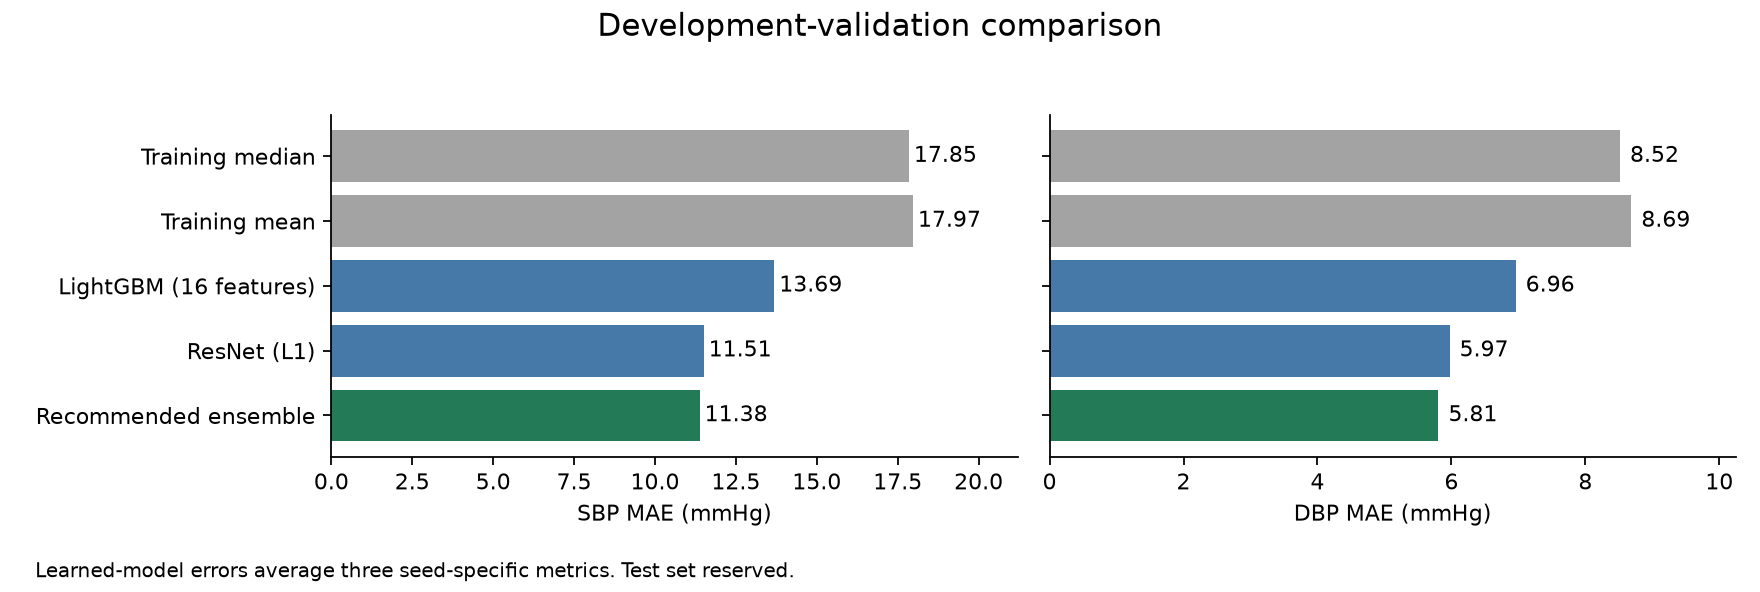

In [9]:
metrics = pd.read_csv(ROOT / 'reports/final/selected_metrics.csv')
order = ['training_median', 'training_mean', 'lightgbm_16', 'resnet_l1', 'recommended']
summary = metrics[metrics['split'].eq('validation')].groupby('model')[
    ['sbp_mae', 'dbp_mae', 'sbp_rmse', 'dbp_rmse']].mean().reindex(order)
display(summary.round(3).rename_axis('Model (errors in mmHg)'))
display(Image(filename=str(ROOT / 'reports/final/plots/selected_comparison.png'), width=950))

## 8. Training and validation evaluation

MAE and RMSE are reported separately for SBP and DBP. The same IDs and labels are used across the final comparison. Mean/median baselines use only training answers. Later selections used recording-grouped holdouts within training. Original validation remains development data; no test scoring is provided.

The table below shows saved training and validation MAE, averaged over the three seed-specific fits. A training/validation gap alone does not identify overfitting, representation limits, or label uncertainty as the single cause.

sbp_mae  dbp_mae
model           split                       
lightgbm_16     train         8.395    4.812
                validation   13.690    6.959
recommended     train         7.649    3.886
                validation   11.384    5.806
resnet_l1       train         7.776    3.977
                validation   11.509    5.972
training_mean   train        18.047    8.428
                validation   17.974    8.686
training_median train        18.002    8.258
                validation   17.850    8.516

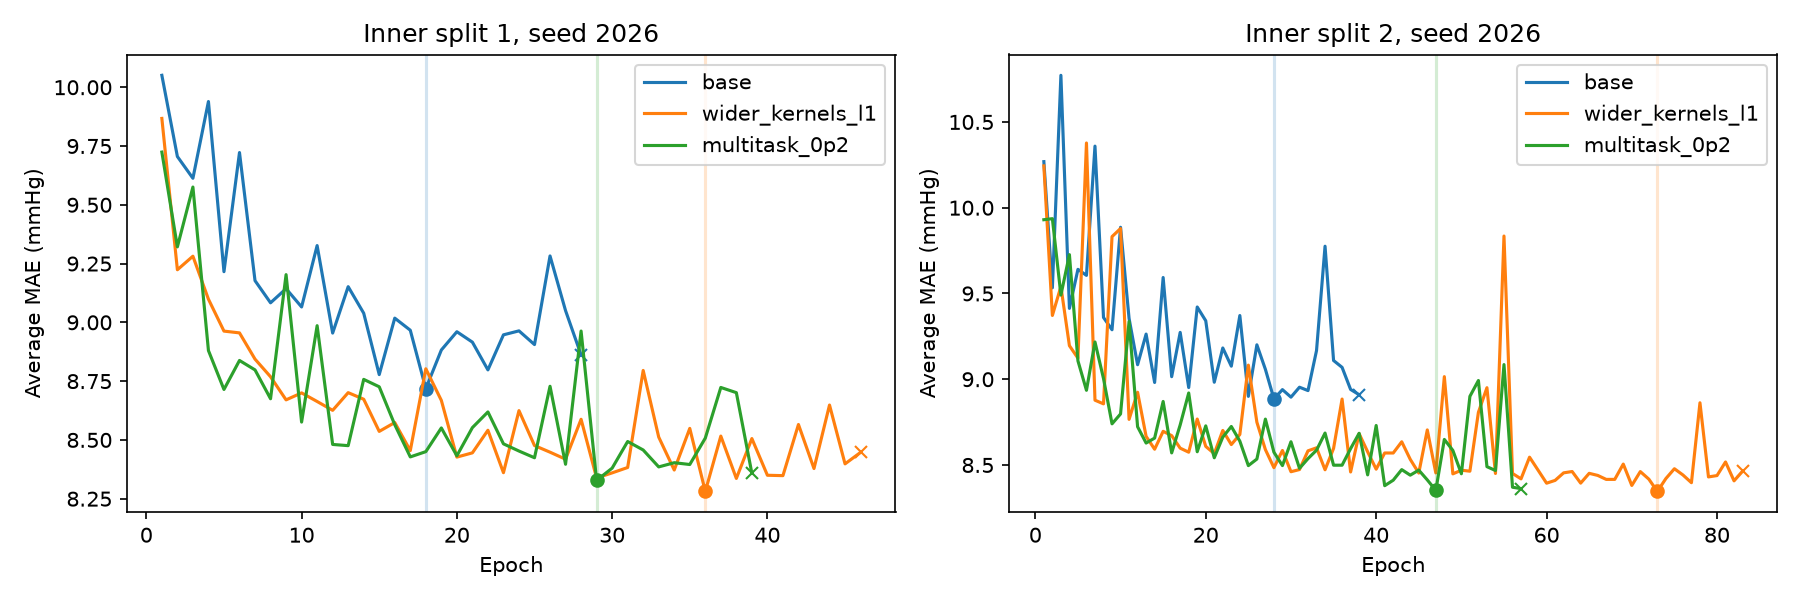

In [10]:
gaps = metrics[metrics['split'].isin(['train', 'validation'])].groupby(['model', 'split'])[
    ['sbp_mae', 'dbp_mae']].mean()
display(gaps.round(3))
display(Image(filename=str(ROOT / 'reports/final/plots/learning_curves.png'), width=1000))

In [11]:
if RUN_EVALUATION:
    from models.selected_models import evaluate_selected
    evaluation_bundle = TRAINED_DIR if RUN_TRAINING else ARTIFACTS
    evaluation = evaluate_selected(DATA_DIR, INPUTS_DIR, evaluation_bundle,
        RUN_ROOT / 'evaluation', model=TRAIN_MODEL, seeds=[SEED],
        splits=('train', 'validation'), device=DEVICE)
    display(evaluation.round(3))
else:
    print('Full cohort prediction/evaluation skipped; saved metrics are displayed above.')

Full cohort prediction/evaluation skipped; saved metrics are displayed above.


## 9. Errors across pressure ranges

The ensemble tends to overpredict low SBP and underpredict high pressures. The matrices group seed-2026 continuous predictions into pressure ranges. They show the ensemble, rather than its auxiliary classifier.

,target,range,windows,recordings,mae,bias
327,dbp,<=60,24244,972,5.134,4.584
328,dbp,>120,160,21,57.601,-57.601
329,dbp,>90,2608,150,27.618,-27.510
334,sbp,<=90,1383,121,22.635,22.356
335,sbp,>180,1042,77,28.480,-28.048


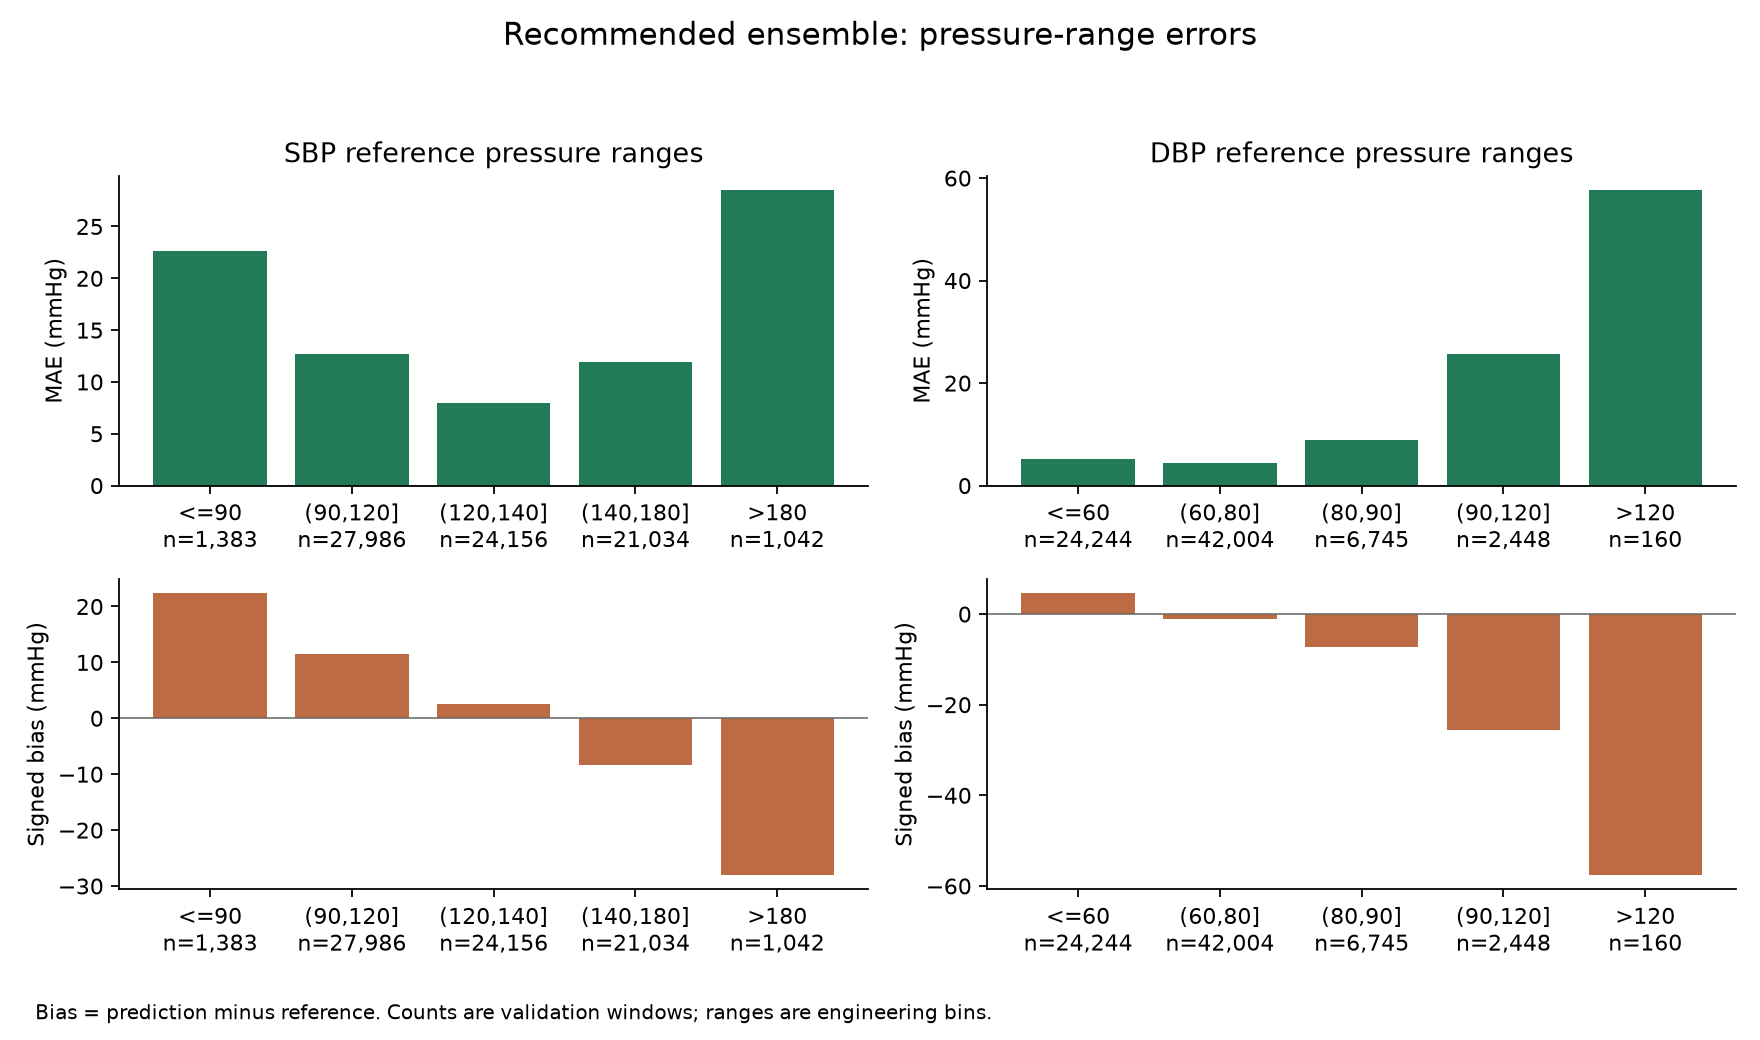

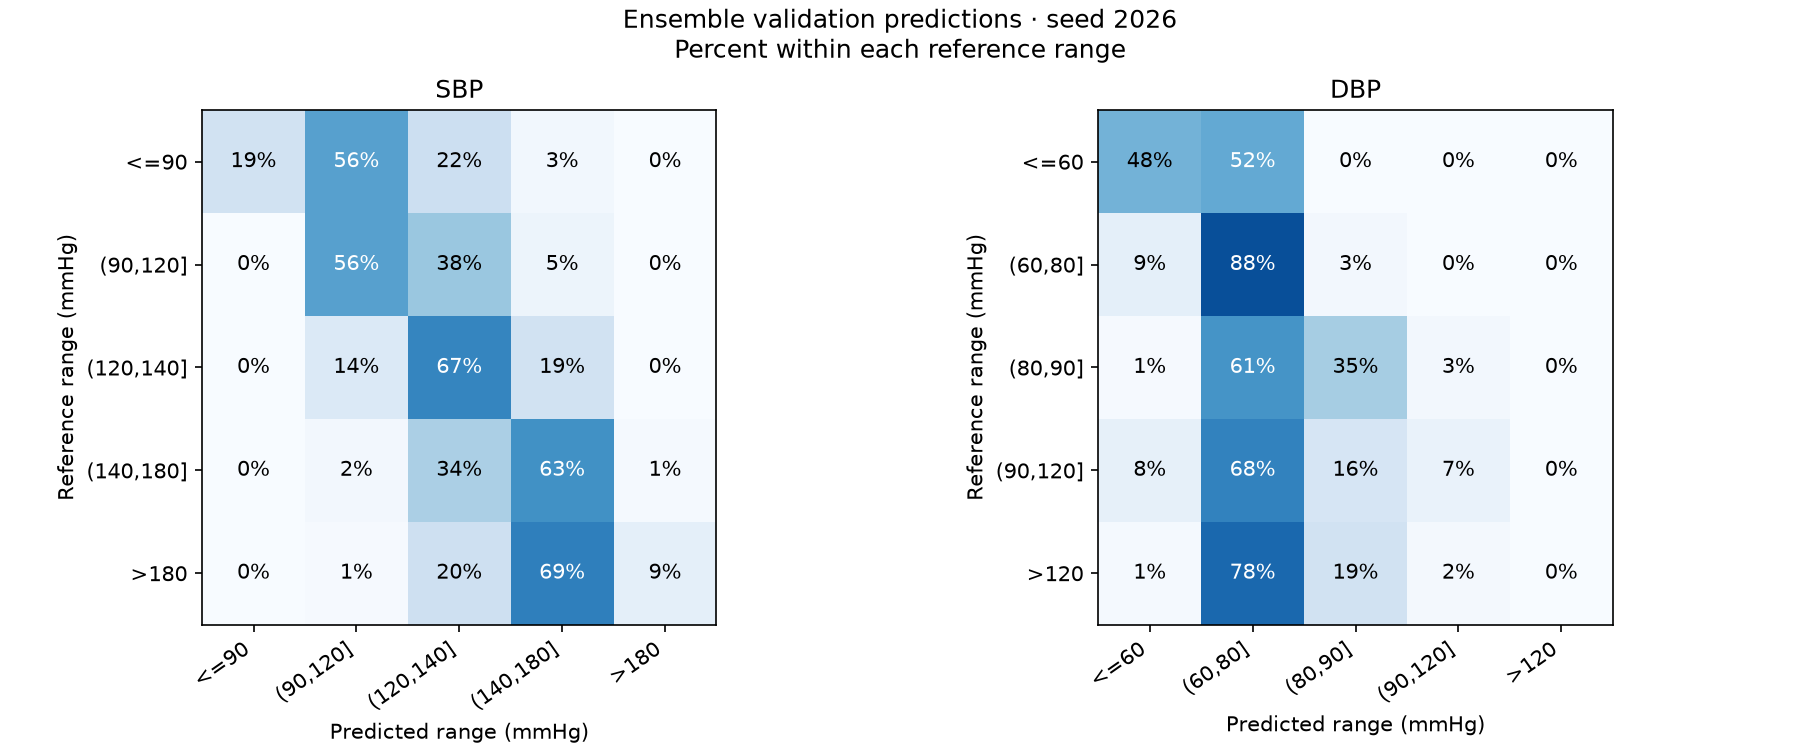

In [12]:
pressure = pd.read_csv(ROOT / 'reports/final/pressure_summary.csv')
tails = pressure[pressure['model'].eq('multitask_0p2_selected_blend')
                 & pressure['split'].eq('validation')
                 & pressure['range'].isin(['<=90', '>180', '<=60', '>90', '>120'])]
display(tails[['target', 'range', 'windows', 'recordings', 'mae', 'bias']].round(3))
display(Image(filename=str(ROOT / 'reports/final/plots/selected_pressure_ranges.png'), width=1000))
display(Image(filename=str(ROOT / 'reports/final/plots/ensemble_confusion.png'), width=1000))

## Limitations

Validation informed development; the test set remains reserved. Recording IDs do not establish patient independence. Errors remain larger at pressure extremes. Earlier experiments are in the optional history archive. See [SETUP.md](../SETUP.md) for workflow instructions.